<a href="https://colab.research.google.com/github/fattah-abdullah/ProyekAkhir_5A_CardiovascularDisease/blob/main/02_Preprosesing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bagian 1 — Persiapan dan pemuatan dataset

### Install Library tambahan (gdown)

In [27]:
!pip -q install gdown

### Import Library

In [28]:
# Import library pengolahan data
import pandas as pd
import numpy as np

# Import library visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Import library tambahan
import os
import gdown

### Load Data dari Google Drive

In [29]:
# Masukkan link Google Drive yang berisi cardio_train.csv
drive_url = "https://drive.google.com/file/d/1WCGgJ-fTcaGpCIRoNXPJNPQuqJzJ_nuD/view?usp=drive_link"

# Nama file lokal setelah diunduh
file_path = "cardio_train.csv"

# Mengunduh dataset dari Google Drive
gdown.download(
    url=drive_url,
    output=file_path,
    fuzzy=True,
    quiet=False
)
df = pd.read_csv(file_path, sep=';')

# Menampilkan informasi awal dataset
print("\nDataset berhasil dimuat!")
print("Nama file:", file_path)

display(df.head())

Downloading...
From: https://drive.google.com/uc?id=1WCGgJ-fTcaGpCIRoNXPJNPQuqJzJ_nuD
To: /content/cardio_train.csv
100%|██████████| 2.94M/2.94M [00:00<00:00, 176MB/s]


Dataset berhasil dimuat!
Nama file: cardio_train.csv


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


# Bagian 2 — Basic Preprocessing (Data Cleaning)

### Membuat salinan dataset

In [30]:
df_clean = df.copy()

jumlah_awal = len(df_clean)

print("Jumlah data sebelum cleaning:", jumlah_awal)

Jumlah data sebelum cleaning: 70000


### Menghapus duplikasi

In [31]:
jumlah_duplikat = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()

print("Jumlah duplikat ditemukan:", jumlah_duplikat)
print("Jumlah data setelah menghapus duplikat:", len(df_clean))

Jumlah duplikat ditemukan: 0
Jumlah data setelah menghapus duplikat: 70000


### Menangani missing values

In [32]:
print("Missing values sebelum penanganan:")
display(df_clean.isnull().sum())

# Menghapus baris yang memiliki missing values,
# jika memang ditemukan.
df_clean = df_clean.dropna()

print("\nMissing values setelah penanganan:")
display(df_clean.isnull().sum())

Missing values sebelum penanganan:


,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0



Missing values setelah penanganan:


,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0


### Melakukan cleaning untuk data tidak valid

In [33]:
numeric_columns = ['ap_hi', 'ap_lo', 'height', 'weight']

jumlah_sebelum = len(df_clean)

# Memastikan seluruh variabel numerik yang diperiksa
# tidak memiliki nilai negatif.
negative_mask = (
    df_clean[numeric_columns] < 0
).any(axis=1)

jumlah_negatif = negative_mask.sum()

df_clean = df_clean[~negative_mask].copy()

print("Jumlah baris dengan nilai negatif:", jumlah_negatif)
print("Jumlah baris yang dihapus:", jumlah_sebelum - len(df_clean))
print("Jumlah data setelah cleaning:", len(df_clean))

Jumlah baris dengan nilai negatif: 8
Jumlah baris yang dihapus: 8
Jumlah data setelah cleaning: 69992


### Validasi hasil cleaning

In [34]:
print("Ukuran dataset:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplikasi:")
print(df_clean.duplicated().sum())

print("\nStatistik deskriptif:")
display(df_clean.describe().T)

Ukuran dataset: (69992, 13)

Missing values:
0

Duplikasi:
0

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
id,69992.0,49973.395702,28851.700988,0.0,25006.75,50003.0,74890.25,99999.0
age,69992.0,19468.869056,2467.087019,10798.0,17664.00,19703.0,21327.00,23713.0
gender,69992.0,1.349554,0.476833,1.0,1.00,1.0,2.00,2.0
height,69992.0,164.359384,8.210423,55.0,159.00,165.0,170.00,250.0
weight,69992.0,74.206485,14.395726,10.0,65.00,72.0,82.00,200.0
ap_hi,69992.0,128.843868,153.999302,1.0,120.00,120.0,140.00,16020.0
ap_lo,69992.0,96.634601,188.482151,0.0,80.00,80.0,90.00,11000.0
cholesterol,69992.0,1.366885,0.680272,1.0,1.00,1.0,2.00,3.0
gluc,69992.0,1.226483,0.572298,1.0,1.00,1.0,1.00,3.0
smoke,69992.0,0.088139,0.283498,0.0,0.00,0.0,0.00,1.0


### Perbandingan sebelum dan sesudah cleaning

In [35]:
jumlah_akhir = len(df_clean)
jumlah_dihapus = jumlah_awal - jumlah_akhir

persentase_dipertahankan = (
    jumlah_akhir / jumlah_awal
) * 100

comparison = pd.DataFrame({
    "Keterangan": [
        "Jumlah data awal",
        "Jumlah data akhir",
        "Jumlah data dihapus",
        "Persentase data dipertahankan"
    ],
    "Nilai": [
        jumlah_awal,
        jumlah_akhir,
        jumlah_dihapus,
        f"{persentase_dipertahankan:.2f}%"
    ]
})

display(comparison)

,Keterangan,Nilai
0,Jumlah data awal,70000
1,Jumlah data akhir,69992
2,Jumlah data dihapus,8
3,Persentase data dipertahankan,99.99%


### Perbandingan distribusi target sebelum dan sesudah cleaning

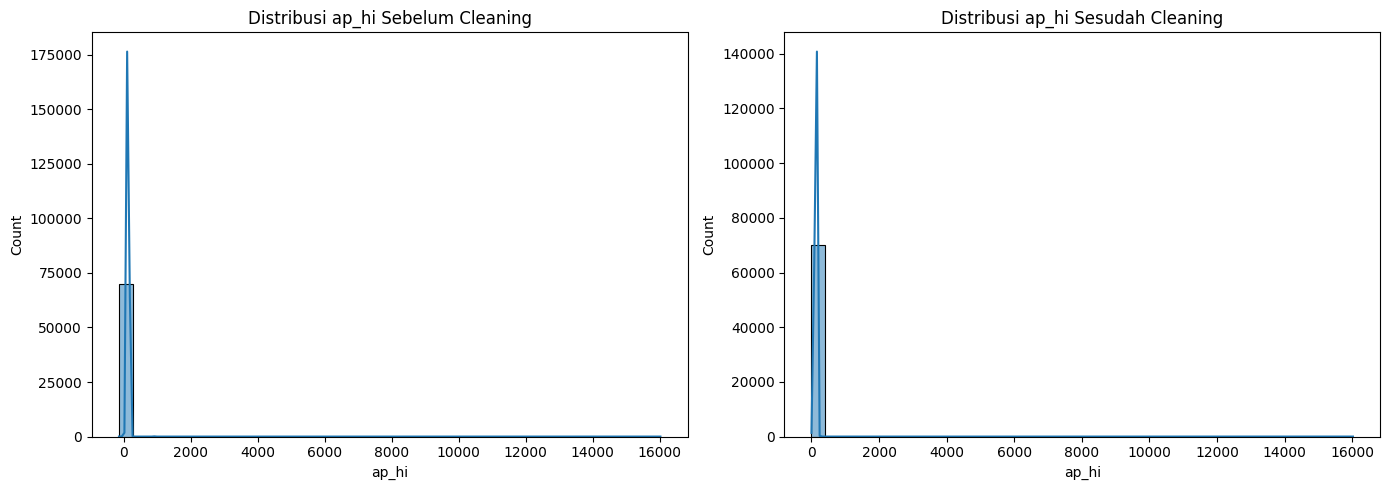

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["ap_hi"],
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribusi ap_hi Sebelum Cleaning")

sns.histplot(
    df_clean["ap_hi"],
    bins=40,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribusi ap_hi Sesudah Cleaning")

plt.tight_layout()
plt.show()

### Menyimpan dataset hasil cleaning

In [37]:
output_clean = "cardio_clean.csv"

df_clean.to_csv(
    output_clean,
    index=False
)

print("Dataset berhasil disimpan:", output_clean)

Dataset berhasil disimpan: cardio_clean.csv
